<a href="https://colab.research.google.com/github/LuisTT0903/Processamento-de-Sinais1/blob/main/Pr%C3%A1tica6Quest%C3%A3o1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

H8 =
 [[ 1  1  1  1  1  1  1  1]
 [ 1 -1  1 -1  1 -1  1 -1]
 [ 1  1 -1 -1  1  1 -1 -1]
 [ 1 -1 -1  1  1 -1 -1  1]
 [ 1  1  1  1 -1 -1 -1 -1]
 [ 1 -1  1 -1 -1  1 -1  1]
 [ 1  1 -1 -1 -1 -1  1  1]
 [ 1 -1 -1  1 -1  1  1 -1]]

C^T C =
 [[8 0 0]
 [0 8 0]
 [0 0 8]]   (= L·I  -> códigos ortogonais)


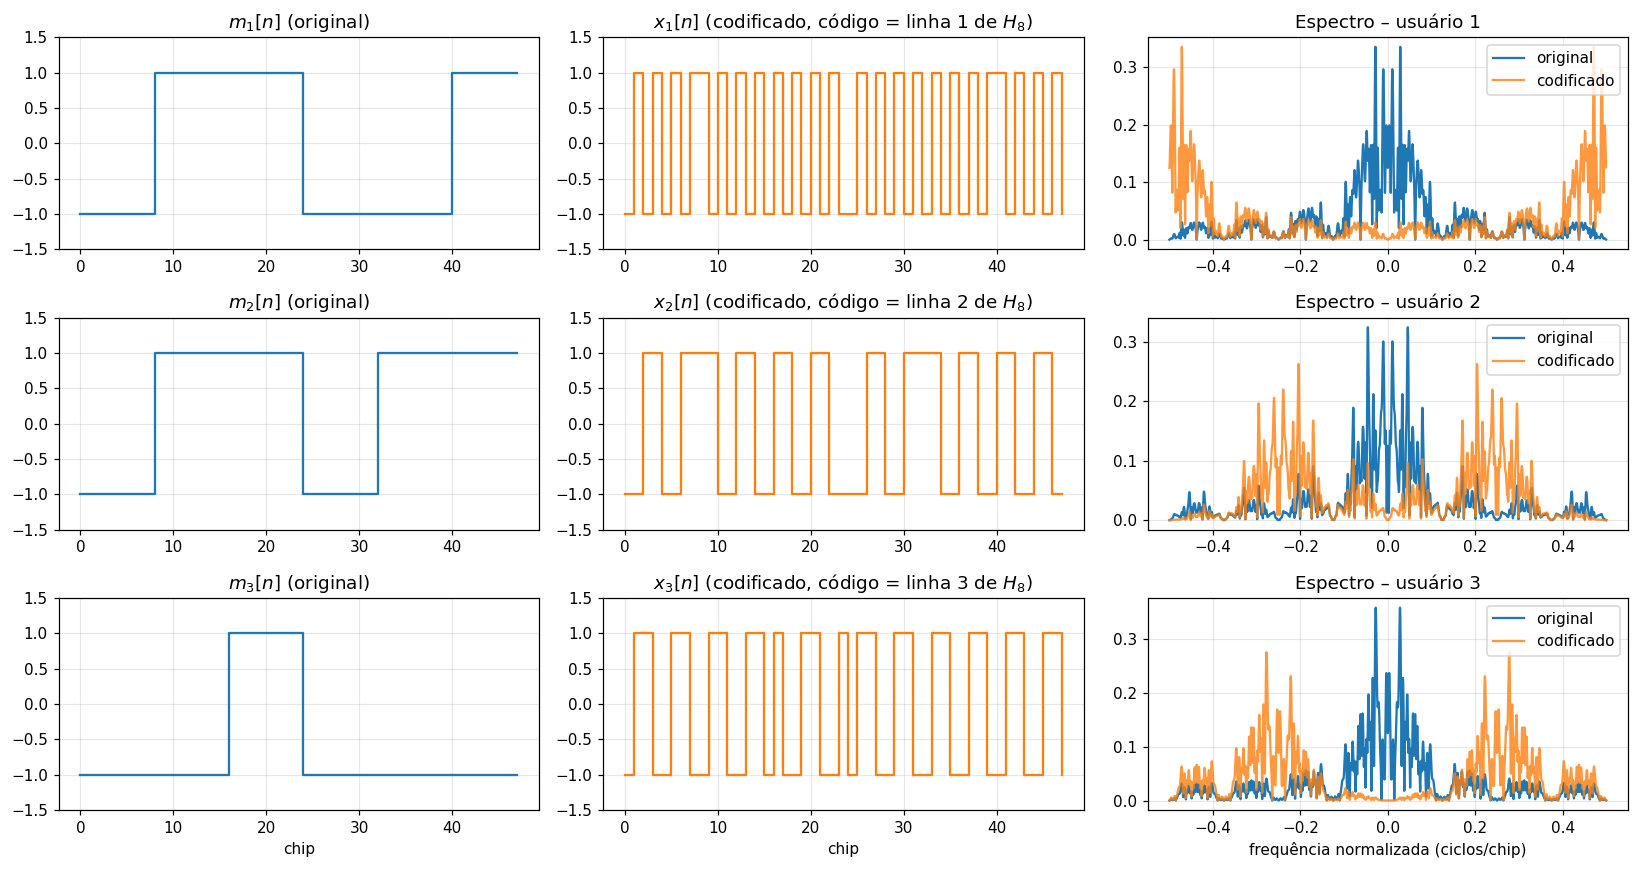

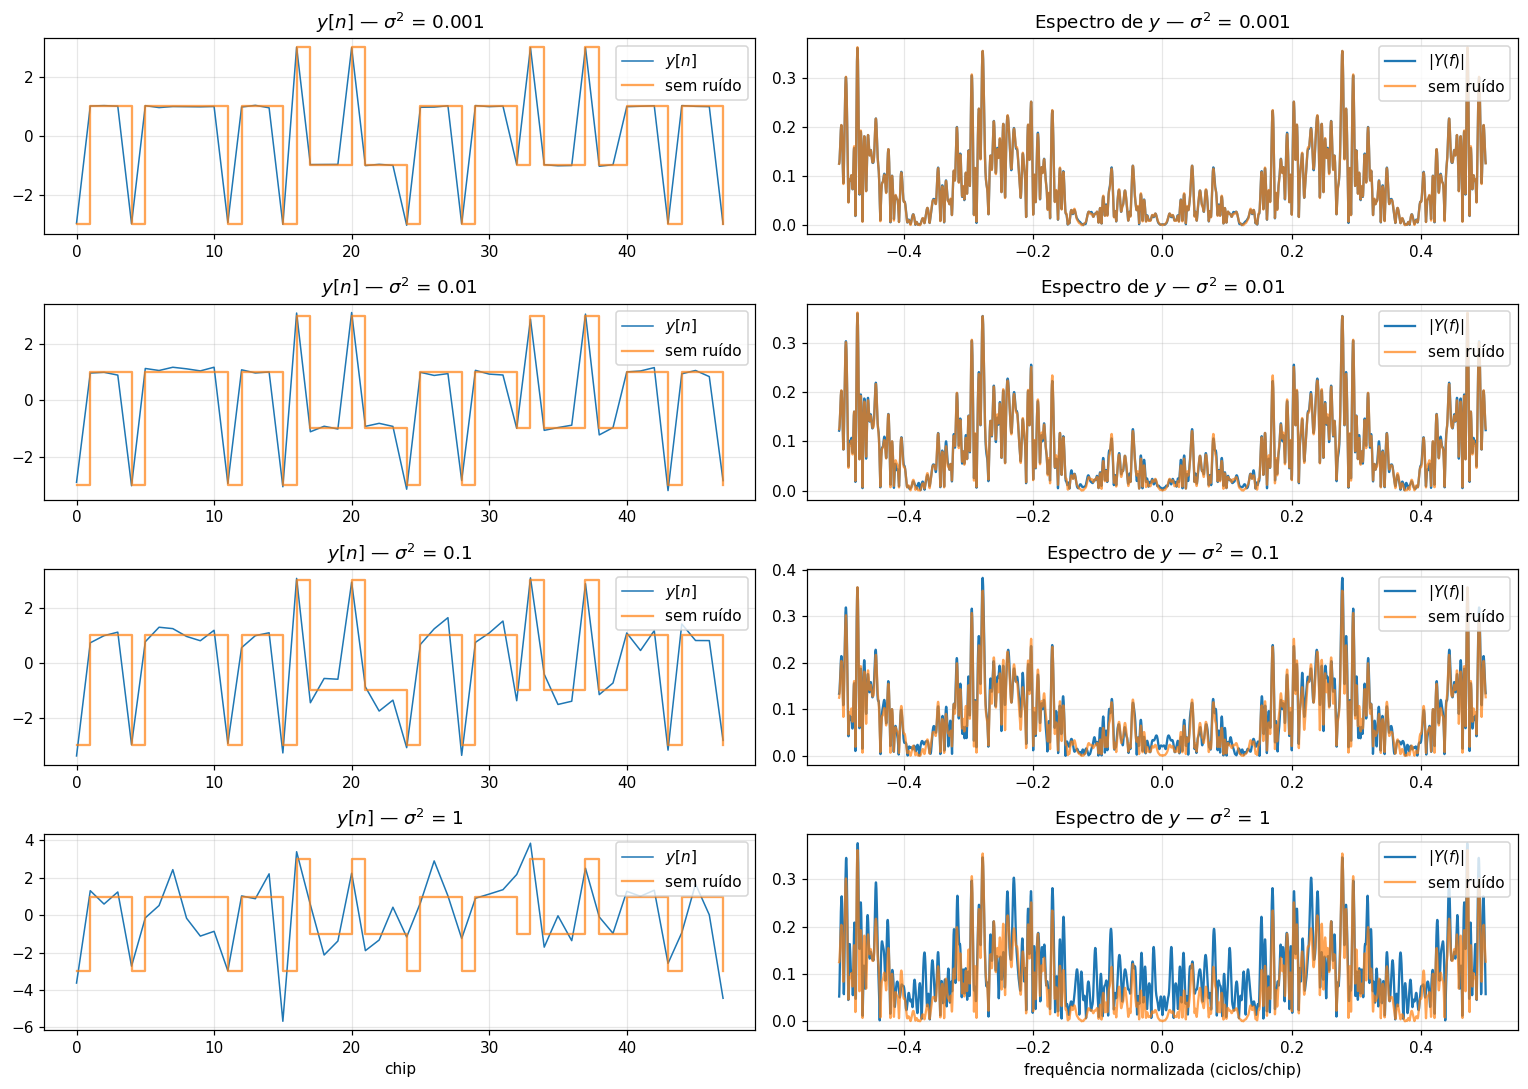

σ² = 0.001   SNR por chip ≈  34.8 dB
σ² = 0.01    SNR por chip ≈  24.8 dB
σ² = 0.1     SNR por chip ≈  14.8 dB
σ² = 1       SNR por chip ≈   4.8 dB
     σ² |  MSE medido | σ²/L teórico | BER medida | Pe teórica
----------------------------------------------------------------
  0.001 |    1.13e-04 |     1.25e-04 |     0.0000 |   0.00e+00
   0.01 |    9.15e-04 |     1.25e-03 |     0.0000 |  2.70e-176
    0.1 |    1.57e-02 |     1.25e-02 |     0.0000 |   1.87e-19
      1 |    1.05e-01 |     1.25e-01 |     0.0000 |   2.34e-03


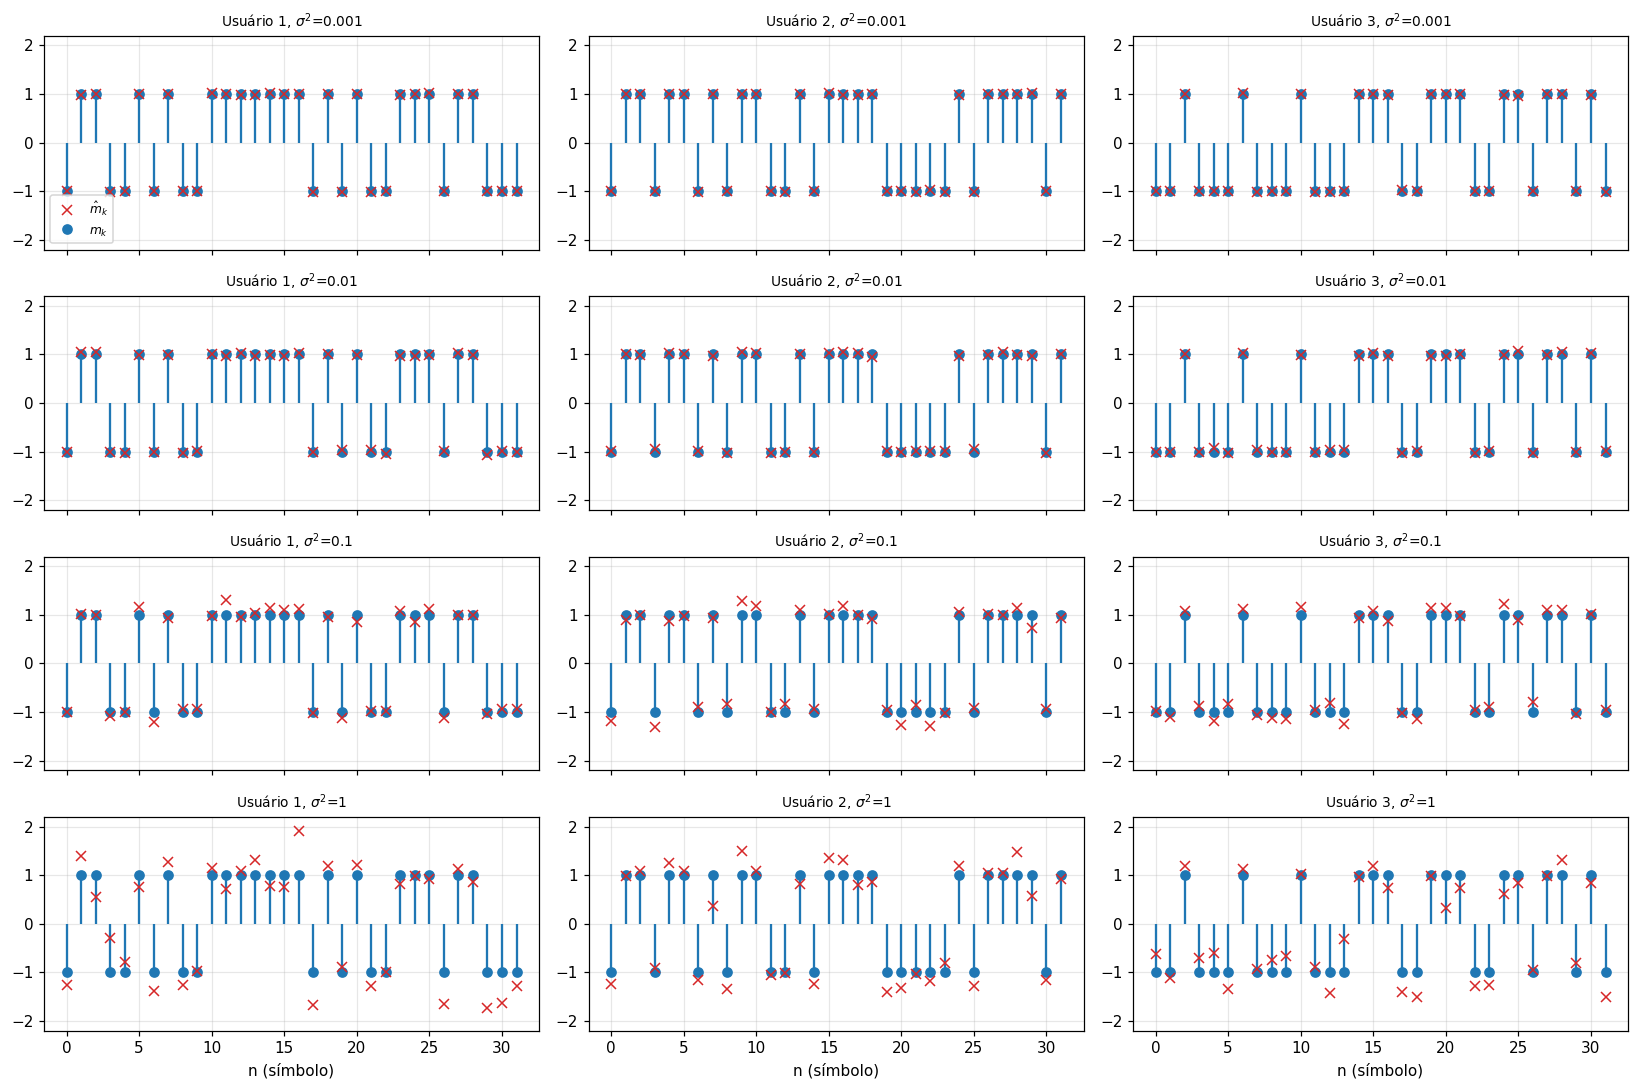

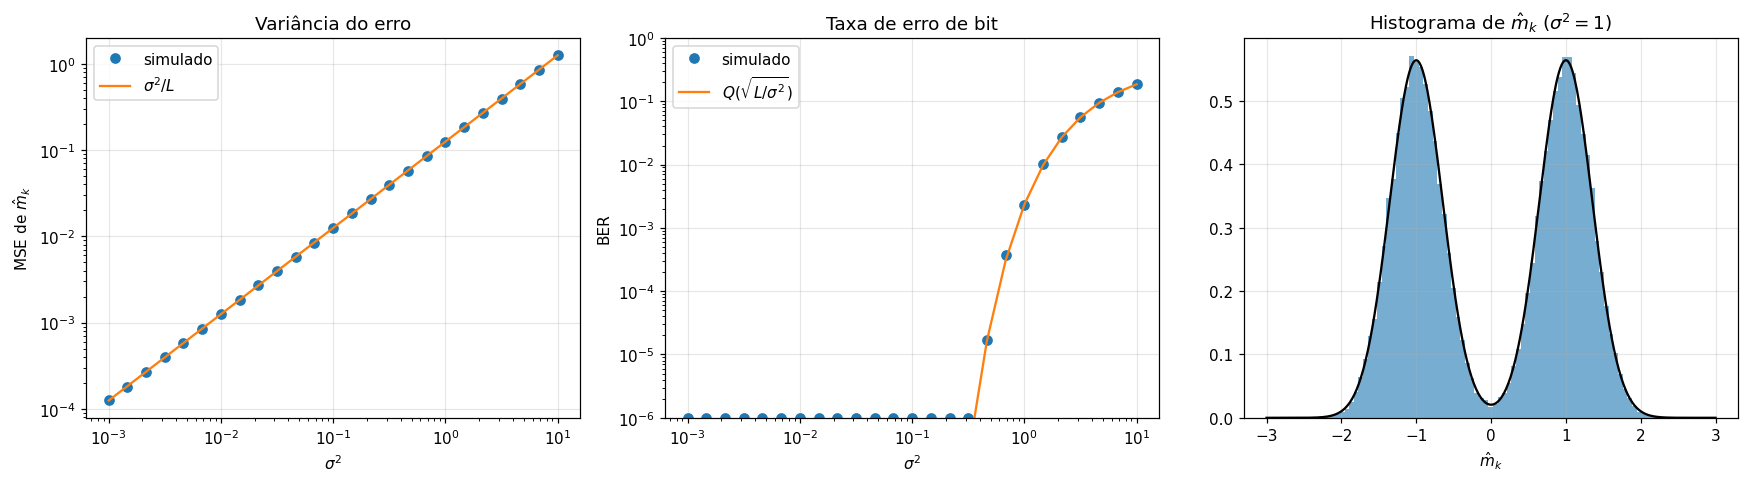

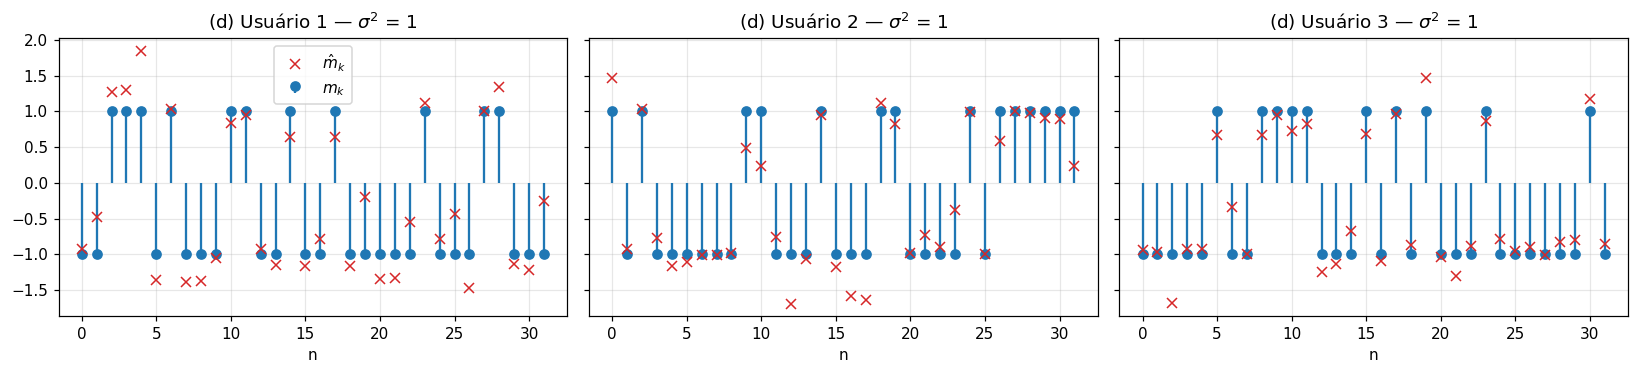

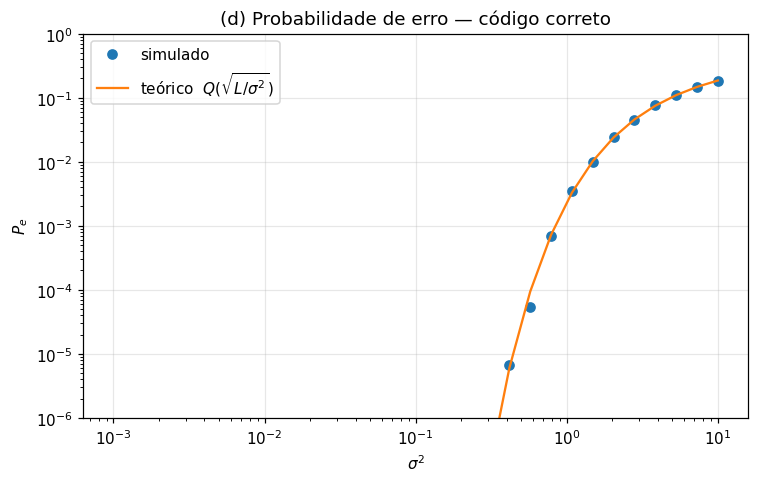


(e) Verificação: m̂ = m + (1/L) W^T C m  ->  OK


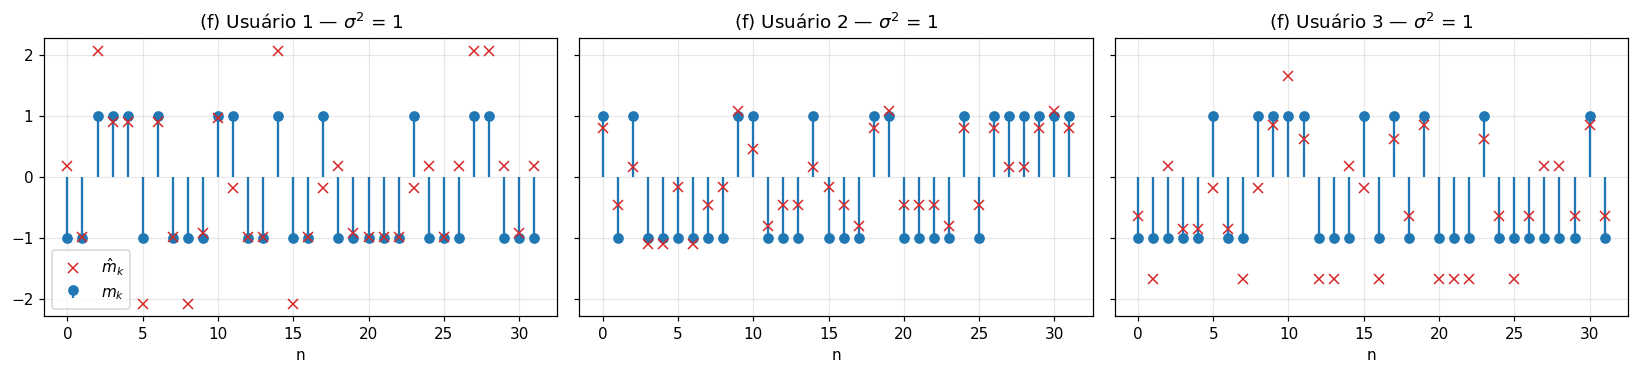

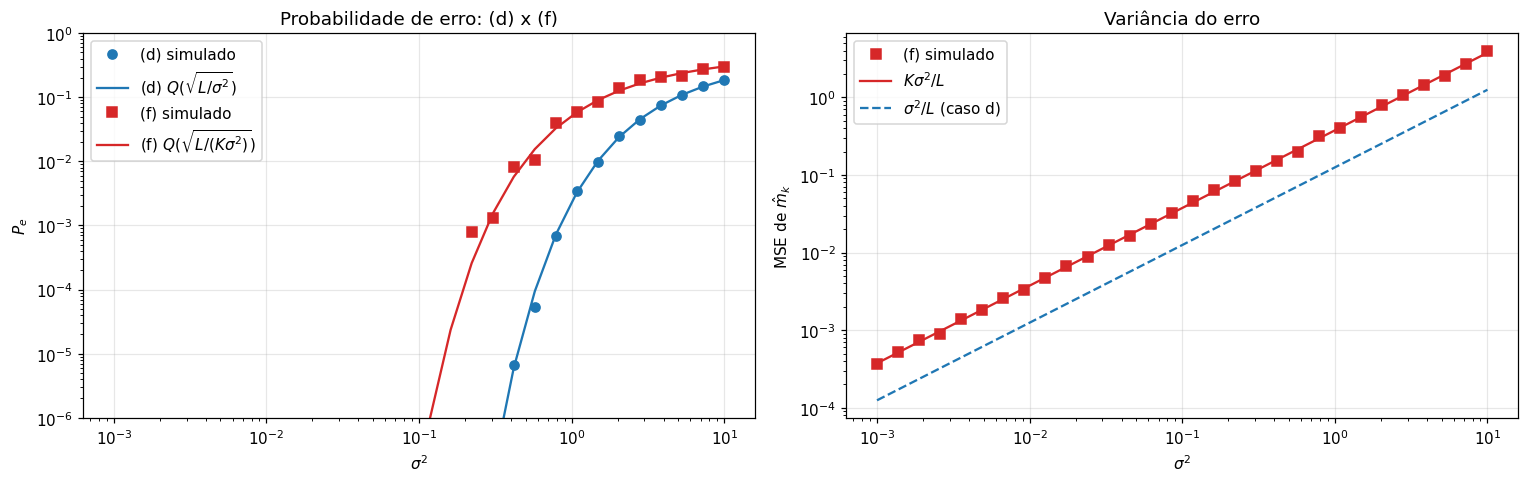


     σ² | Pe (d) sim | Pe (d) teo | Pe (f) sim | Pe (f) teo
------------------------------------------------------------
  0.001 |   0.00e+00 |   0.00e+00 |   0.00e+00 |   0.00e+00
0.00924 |   0.00e+00 |  1.14e-190 |   0.00e+00 |   4.77e-65
 0.0853 |   0.00e+00 |   1.77e-22 |   0.00e+00 |   1.13e-08
   1.08 |   3.51e-03 |   3.28e-03 |   5.87e-02 |   5.83e-02


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import hadamard

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
rng = np.random.default_rng(42)


L = 8
K = 3
N = 32

H = hadamard(L)
codigos_idx = [1, 2, 3]
Cmat = H[codigos_idx].T
print('H8 =\n', H)
print('\nC^T C =\n', Cmat.T @ Cmat, '  (= L·I  -> códigos ortogonais)')


M = rng.choice([-1, 1], size=(K, N))
X = np.array([np.kron(M[k], Cmat[:, k]) for k in range(K)])
M_up = np.repeat(M, L, axis=1)

def espectro(x, nfft=4096):
    Xf = np.fft.fftshift(np.fft.fft(x, nfft)) / len(x)
    f = np.fft.fftshift(np.fft.fftfreq(nfft))
    return f, np.abs(Xf)

nmostra = 6 * L
t = np.arange(nmostra)
fig, ax = plt.subplots(K, 3, figsize=(15, 8))
for k in range(K):
    ax[k, 0].step(t, M_up[k, :nmostra], where='post')
    ax[k, 0].set_title(f'$m_{k+1}[n]$ (original)')
    ax[k, 1].step(t, X[k, :nmostra], where='post', color='C1')
    ax[k, 1].set_title(f'$x_{k+1}[n]$ (codificado, código = linha {codigos_idx[k]} de $H_8$)')
    f, Sm = espectro(M_up[k]); _, Sx = espectro(X[k])
    ax[k, 2].plot(f, Sm, label='original'); ax[k, 2].plot(f, Sx, label='codificado', alpha=0.8)
    ax[k, 2].set_title(f'Espectro – usuário {k+1}'); ax[k, 2].legend()
for a in ax[:, :2].ravel(): a.set_ylim(-1.5, 1.5)
ax[-1, 0].set_xlabel('chip'); ax[-1, 1].set_xlabel('chip'); ax[-1, 2].set_xlabel('frequência normalizada (ciclos/chip)')
plt.tight_layout(); plt.show()


sigmas2 = [1e-3, 1e-2, 1e-1, 1]
x_soma = X.sum(axis=0)
Y = {s2: x_soma + rng.normal(0, np.sqrt(s2), x_soma.size) for s2 in sigmas2}

fig, ax = plt.subplots(len(sigmas2), 2, figsize=(14, 10))
for i, s2 in enumerate(sigmas2):
    ax[i, 0].plot(t, Y[s2][:nmostra], label='$y[n]$', lw=1)
    ax[i, 0].step(t, x_soma[:nmostra], where='post', label='sem ruído', alpha=0.7)
    ax[i, 0].set_title(f'$y[n]$ — $\\sigma^2$ = {s2:g}'); ax[i, 0].legend(loc='upper right')
    f, Sy = espectro(Y[s2]); _, Sx = espectro(x_soma)
    ax[i, 1].plot(f, Sy, label='$|Y(f)|$'); ax[i, 1].plot(f, Sx, label='sem ruído', alpha=0.7)
    ax[i, 1].set_title(f'Espectro de $y$ — $\\sigma^2$ = {s2:g}'); ax[i, 1].legend(loc='upper right')
ax[-1, 0].set_xlabel('chip'); ax[-1, 1].set_xlabel('frequência normalizada (ciclos/chip)')
plt.tight_layout(); plt.show()

for s2 in sigmas2:
    snr = 10*np.log10(np.mean(x_soma**2)/s2)
    print(f'σ² = {s2:<6g}  SNR por chip ≈ {snr:5.1f} dB')


from scipy.stats import norm

def desespalha(y, Cmat, L):
    Yb = y.reshape(-1, L)
    return (Yb @ Cmat).T / L

print(f'{"σ²":>7} | {"MSE medido":>11} | {"σ²/L teórico":>12} | {"BER medida":>10} | {"Pe teórica":>10}')
print('-'*64)
Mhat = {}
for s2 in sigmas2:
    Mhat[s2] = desespalha(Y[s2], Cmat, L)
    mse = np.mean((Mhat[s2] - M)**2)
    ber = np.mean(np.sign(Mhat[s2]) != M)
    pe = norm.sf(np.sqrt(L/s2))
    print(f'{s2:>7g} | {mse:>11.2e} | {s2/L:>12.2e} | {ber:>10.4f} | {pe:>10.2e}')


assert np.allclose(desespalha(x_soma, Cmat, L), M)


n = np.arange(N)
fig, ax = plt.subplots(len(sigmas2), K, figsize=(15, 10), sharex=True)
for i, s2 in enumerate(sigmas2):
    for k in range(K):
        ax[i, k].stem(n, M[k], linefmt='C0-', markerfmt='C0o', basefmt=' ', label='$m_k$')
        ax[i, k].plot(n, Mhat[s2][k], 'C3x', ms=7, label='$\\hat m_k$')
        ax[i, k].set_ylim(-2.2, 2.2)
        ax[i, k].set_title(f'Usuário {k+1}, $\\sigma^2$={s2:g}', fontsize=9)
ax[0, 0].legend(loc='lower left', fontsize=8)
for k in range(K): ax[-1, k].set_xlabel('n (símbolo)')
plt.tight_layout(); plt.show()


Nmc = 20000
s2_grid = np.logspace(-3, 1, 25)
mse_mc, ber_mc = [], []
Mmc = rng.choice([-1, 1], size=(K, Nmc))
xmc = sum(np.kron(Mmc[k], Cmat[:, k]) for k in range(K))
for s2 in s2_grid:
    Mh = desespalha(xmc + rng.normal(0, np.sqrt(s2), xmc.size), Cmat, L)
    mse_mc.append(np.mean((Mh - Mmc)**2)); ber_mc.append(np.mean(np.sign(Mh) != Mmc))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].loglog(s2_grid, mse_mc, 'o', label='simulado'); ax[0].loglog(s2_grid, s2_grid/L, '-', label='$\\sigma^2/L$')
ax[0].set_xlabel('$\\sigma^2$'); ax[0].set_ylabel('MSE de $\\hat m_k$'); ax[0].legend(); ax[0].set_title('Variância do erro')
ax[1].semilogy(s2_grid, np.maximum(ber_mc, 1e-6), 'o', label='simulado')
ax[1].semilogy(s2_grid, norm.sf(np.sqrt(L/s2_grid)), '-', label='$Q(\\sqrt{L/\\sigma^2})$')
ax[1].set_xscale('log'); ax[1].set_ylim(1e-6, 1); ax[1].set_xlabel('$\\sigma^2$'); ax[1].set_ylabel('BER'); ax[1].legend(); ax[1].set_title('Taxa de erro de bit')
s2 = 1.0
Mh = desespalha(xmc + rng.normal(0, 1, xmc.size), Cmat, L)
ax[2].hist(Mh.ravel(), bins=80, density=True, alpha=0.6)
u = np.linspace(-3, 3, 400)
pdf = 0.5*norm.pdf(u, 1, np.sqrt(s2/L)) + 0.5*norm.pdf(u, -1, np.sqrt(s2/L))
ax[2].plot(u, pdf, 'k'); ax[2].set_title('Histograma de $\\hat m_k$ ($\\sigma^2=1$)'); ax[2].set_xlabel('$\\hat m_k$')
plt.tight_layout(); plt.show()


s2_grid = np.logspace(-3, 1, 30)
Nd = 50000
Md = rng.choice([-1, 1], size=(K, Nd))
xd = sum(np.kron(Md[k], Cmat[:, k]) for k in range(K))

ber_d = []
for s2 in s2_grid:
    yd = xd + rng.normal(0, np.sqrt(s2), xd.size)
    Mh = desespalha(yd, Cmat, L)
    ber_d.append(np.mean(np.sign(Mh) != Md))
ber_d = np.array(ber_d)
pe_d = norm.sf(np.sqrt(L / s2_grid))


s2_ex = 1.0
Mh_ex = desespalha(xd[:32*L] + rng.normal(0, np.sqrt(s2_ex), 32*L), Cmat, L)
fig, ax = plt.subplots(1, K, figsize=(15, 3.5), sharey=True)
for k in range(K):
    ax[k].stem(np.arange(32), Md[k, :32], linefmt='C0-', markerfmt='C0o', basefmt=' ', label='$m_k$')
    ax[k].plot(np.arange(32), Mh_ex[k], 'C3x', ms=7, label='$\\hat m_k$')
    ax[k].set_title(f'(d) Usuário {k+1} — $\\sigma^2$ = {s2_ex:g}'); ax[k].set_xlabel('n')
ax[0].legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 4.5))
plt.semilogy(s2_grid, np.where(ber_d > 0, ber_d, np.nan), 'o', label='simulado')
plt.semilogy(s2_grid, pe_d, '-', label='teórico  $Q(\\sqrt{L/\\sigma^2})$')
plt.xscale('log'); plt.ylim(1e-6, 1)
plt.xlabel('$\\sigma^2$'); plt.ylabel('$P_e$'); plt.title('(d) Probabilidade de erro — código correto')
plt.legend(); plt.tight_layout(); plt.show()


Cfull = H.astype(float)
idx = codigos_idx


m_test = np.zeros(L); m_test[idx] = rng.choice([-1, 1], K)
W_test = rng.normal(0, np.sqrt(0.1), (L, L))
mh_direto = (Cfull + W_test).T @ (Cfull @ m_test) / L
mh_formula = m_test + W_test.T @ Cfull @ m_test / L
assert np.allclose(mh_direto, mh_formula)
print('\n(e) Verificação: m̂ = m + (1/L) W^T C m  ->  OK')


n_W = 200
Ns = 500

ber_f, mse_f = [], []
for s2 in s2_grid:
    erros, se, total = 0, 0.0, 0
    for _ in range(n_W):
        Wr = rng.normal(0, np.sqrt(s2), (L, L))
        Chat = Cfull + Wr
        Mf = np.zeros((L, Ns)); Mf[idx] = rng.choice([-1, 1], (K, Ns))
        Yf = Cfull @ Mf
        Mh = (Chat.T @ Yf / L)[idx]
        erros += np.sum(np.sign(Mh) != Mf[idx]); se += np.sum((Mh - Mf[idx])**2); total += Mh.size
    ber_f.append(erros / total); mse_f.append(se / total)
ber_f, mse_f = np.array(ber_f), np.array(mse_f)
pe_f = norm.sf(np.sqrt(L / (K * s2_grid)))


Wr = rng.normal(0, np.sqrt(s2_ex), (L, L))
Mf = np.zeros((L, 32)); Mf[idx] = Md[:, :32]
Mh_f = ((Cfull + Wr).T @ (Cfull @ Mf) / L)[idx]
fig, ax = plt.subplots(1, K, figsize=(15, 3.5), sharey=True)
for k in range(K):
    ax[k].stem(np.arange(32), Md[k, :32], linefmt='C0-', markerfmt='C0o', basefmt=' ', label='$m_k$')
    ax[k].plot(np.arange(32), Mh_f[k], 'C3x', ms=7, label='$\\hat m_k$')
    ax[k].set_title(f'(f) Usuário {k+1} — $\\sigma^2$ = {s2_ex:g}'); ax[k].set_xlabel('n')
ax[0].legend(); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].semilogy(s2_grid, np.where(ber_d > 0, ber_d, np.nan), 'o', label='(d) simulado')
ax[0].semilogy(s2_grid, pe_d, 'C0-', label='(d) $Q(\\sqrt{L/\\sigma^2})$')
ax[0].semilogy(s2_grid, np.where(ber_f > 0, ber_f, np.nan), 's', color='C3', label='(f) simulado')
ax[0].semilogy(s2_grid, pe_f, 'C3-', label='(f) $Q(\\sqrt{L/(K\\sigma^2)})$')
ax[0].set_xscale('log'); ax[0].set_ylim(1e-6, 1)
ax[0].set_xlabel('$\\sigma^2$'); ax[0].set_ylabel('$P_e$'); ax[0].set_title('Probabilidade de erro: (d) x (f)'); ax[0].legend()
ax[1].loglog(s2_grid, mse_f, 's', color='C3', label='(f) simulado')
ax[1].loglog(s2_grid, K * s2_grid / L, 'C3-', label='$K\\sigma^2/L$')
ax[1].loglog(s2_grid, s2_grid / L, 'C0--', label='$\\sigma^2/L$ (caso d)')
ax[1].set_xlabel('$\\sigma^2$'); ax[1].set_ylabel('MSE de $\\hat m_k$'); ax[1].set_title('Variância do erro'); ax[1].legend()
plt.tight_layout(); plt.show()

print(f'\n{"σ²":>7} | {"Pe (d) sim":>10} | {"Pe (d) teo":>10} | {"Pe (f) sim":>10} | {"Pe (f) teo":>10}')
print('-' * 60)
for s2 in [1e-3, 1e-2, 1e-1, 1]:
    i = np.argmin(np.abs(s2_grid - s2))
    print(f'{s2_grid[i]:>7.3g} | {ber_d[i]:>10.2e} | {pe_d[i]:>10.2e} | {ber_f[i]:>10.2e} | {pe_f[i]:>10.2e}')

(a)
Os sinais originais m1[n], m2[n] e m3[n] são sequências aleatórias de +1 e -1. Na taxa de chip, cada símbolo dura 8 amostras, então o espectro deles fica concentrado em torno da frequência zero, com um lóbulo principal estreito (largura da ordem de 1/8 ciclo por chip). Depois da codificação, cada símbolo passa a ser multiplicado pelos 8 chips do código, e o sinal troca de sinal muitas vezes dentro de um mesmo símbolo. O resultado nos gráficos é que o espectro sai da região de baixas frequências e se espalha por uma banda cerca de 8 vezes maior, que é o ganho de processamento do sistema. O código do usuário 1 alterna a cada chip, então a energia dele foi para perto de f = 0,5 ciclo por chip. Os códigos dos usuários 2 e 3 têm período de 4 chips, então a energia deles ficou em torno de f = 0,25 ciclo por chip. Os usuários 2 e 3 ocupam praticamente a mesma faixa de frequência, o que mostra que a separação entre usuários no CDMA não é feita pela frequência, e sim pela ortogonalidade dos códigos.

(b)
Sem ruído, o sinal recebido é a soma dos três sinais codificados e só assume os níveis -3, -1, 1 e 3. Para sigma² = 0,001 e 0,01, o sinal recebido praticamente coincide com o transmitido, tanto no tempo quanto no espectro, com relações sinal-ruído por chip de 34,8 dB e 24,8 dB. Para sigma² = 0,1 (14,8 dB), os níveis ficam visivelmente borrados, mas ainda distinguíveis. Para sigma² = 1 (4,8 dB), os níveis se misturam e não é mais possível identificar a soma dos sinais olhando para y[n]. No espectro, o ruído aparece como um piso plano somado a todas as frequências, que sobe junto com sigma². Para sigma² = 1, esse piso fica com amplitude comparável à do próprio sinal.

(c)
Para recuperar m_k[n], o receptor divide y[n] em blocos de 8 chips e calcula a correlação de cada bloco com o código do usuário k, dividindo o resultado por 8. Como os códigos de Hadamard são ortogonais, a contribuição dos outros dois usuários se anula por completo, e a estimativa fica igual ao símbolo transmitido mais um termo de ruído. Esse termo é gaussiano, tem média zero e variância sigma²/8, ou seja, o despreading reduz a potência do ruído por um fator 8 (cerca de 9 dB). Os resultados confirmam isso: o erro quadrático médio medido foi de 1,1e-4, 9,2e-4, 1,6e-2 e 1,1e-1 para os quatro valores de sigma², contra os valores teóricos de 1,25e-4, 1,25e-3, 1,25e-2 e 1,25e-1. Sem ruído, a recuperação foi exata. Nos 32 símbolos de cada usuário não houve nenhum erro de decisão, nem mesmo para sigma² = 1, apesar de y[n] estar bastante degradado nesse caso.

(d)
A decisão sobre cada símbolo é feita pelo sinal da estimativa. Pelo gráfico, a probabilidade de erro é desprezível para sigma² abaixo de cerca de 0,1: nenhum erro ocorreu em 50 000 símbolos por usuário nessa faixa. A partir de sigma² em torno de 0,5, os erros começam a aparecer e a curva sobe rapidamente. Para sigma² próximo de 1, a probabilidade de erro simulada foi de 3,5e-3, muito próxima do valor teórico de 3,3e-3, e os pontos simulados acompanham a curva teórica Q(raiz(8/sigma²)) em toda a faixa. Esse desempenho só é possível por causa do ganho de processamento: se não houvesse espalhamento, a probabilidade de erro para sigma² = 1 seria de aproximadamente 0,16, quase cinquenta vezes maior.

(e)
Com w[n] = 0, o sinal recebido é exatamente C vezes m. O receptor, porém, usa a matriz distorcida C + W no lugar de C. Ao fazer a correlação, a parte que vem de C devolve o próprio m, porque o produto de C transposta por C é 8 vezes a identidade. A parte que vem de W gera um termo extra igual a (1/8) vezes W transposta vezes C vezes m. Assim, a estimativa passa a ser o símbolo correto mais esse termo de erro. Para cada usuário, o erro tem duas componentes. A primeira é um ganho aleatório aplicado ao próprio símbolo, ou seja, um erro multiplicativo. A segunda é a soma dos símbolos dos outros usuários, cada um ponderado pela correlação entre a coluna distorcida e o código desse outro usuário, ou seja, interferência de múltiplo acesso. Como as entradas de W são gaussianas independentes com variância sigma², cada uma dessas correlações tem variância 8 sigma², e as correlações com códigos diferentes são independentes entre si, porque os códigos são ortogonais. Somando as contribuições dos 3 usuários ativos, o erro da estimativa tem média zero e variância 3 sigma²/8, e a probabilidade de erro passa a ser Q(raiz(8/(3 sigma²))). Comparado com o item (d), a distorção destrói a ortogonalidade entre os códigos, faz os outros usuários interferirem e torna o erro proporcional ao sinal transmitido, de modo que aumentar a potência de transmissão não resolve o problema. A expressão foi verificada numericamente no código.

(f)
Mesmo sem nenhum ruído no canal, o receptor passa a cometer erros. Nos gráficos de comparação, as estimativas ficam mais espalhadas em torno de +1 e -1 do que no item (d) para o mesmo sigma². Para sigma² próximo de 1, a probabilidade de erro simulada foi de 5,9e-2, contra 5,8e-2 previsto pela teoria, enquanto no item (d) era de 3,5e-3, cerca de dezessete vezes menor. A curva de probabilidade de erro tem a mesma forma da do item (d), mas está deslocada para a esquerda por um fator 3 em sigma², o que equivale a uma perda de cerca de 4,8 dB. O erro quadrático médio medido seguiu 3 sigma²/8, três vezes o valor do item (d). Isso acontece porque, além do ruído sobre o próprio símbolo, cada usuário passa a receber interferência dos outros dois. Se os 8 códigos estivessem em uso, o fator seria 8 e a perda de cerca de 9 dB anularia todo o ganho de processamento. Isso mostra que, no CDMA, é essencial que o receptor tenha uma cópia fiel do código usado na transmissão.